# Phase 2 package vulnerability analysis

Team: Manik Kashikar, Praveen Kumar, Sankeerth Reddy.

In [7]:
pip install duckdb

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from pathlib import Path
import os, json, hashlib
import duckdb
import yaml
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
if not (ROOT / 'config/phase2.yaml').exists():
    ROOT = ROOT.parent
config_file = Path(os.environ.get('PHASE2_CONFIG', 'config/phase2.yaml'))
if not config_file.is_absolute():
    config_file = ROOT / config_file
CONFIG = yaml.safe_load(config_file.read_text(encoding='utf-8'))
def configured_path(value):
    path = Path(value)
    return path if path.is_absolute() else ROOT / path
RESULTS = configured_path(CONFIG.get('results_dir', 'results'))
FIGURES = configured_path(CONFIG.get('figures_dir', 'figures'))
processed = configured_path(CONFIG.get('output_dir', 'data/processed')) / 'associations.parquet'
assert processed.is_file(), 'Run python -m src.pipeline --config config/phase2.yaml first'
A = json.loads((RESULTS / 'analytics.json').read_text(encoding='utf-8'))
with processed.open('rb') as stream:
    assert hashlib.file_digest(stream, 'sha256').hexdigest() == A['processed_sha256']
con = duckdb.connect()
con.execute("SET memory_limit='512MB'")
con.read_parquet(str(processed)).create_view('a')
actual = con.execute('SELECT count(*) FROM a').fetchone()[0]
assert actual == A['totals']['associations']
print('Configured processed file:', processed)
print('Reloaded full processed population:', format(actual, ','), 'associations')
print(json.dumps(A['totals'], indent=2))

Configured processed file: F:\DIC project files\DIC_github_READY\DIC_Phase2_FINAL_COMPLETE\data\processed\associations.parquet
Reloaded full processed population: 884,137 associations
{
  "associations": 884137,
  "packages": 17583,
  "versions": 279284,
  "advisory_ids": 24586,
  "ecosystem_advisory_ids": 26640
}


## Grain and scope

The package key is ecosystem plus package name; the version key adds version; the association key adds advisory ID. Raw advisory IDs may be unresolved aliases, so 24,586 raw IDs and 26,640 ecosystem-advisory pairs are different counts. The CSV records only observed vulnerable associations. It supplies neither a complete-release denominator nor genuine release dates or resolved dependency edges, preventing prevalence, recency and direct/transitive fractions.

In [9]:
assert con.execute('SELECT count(*) FROM a WHERE severity_score < 0 OR severity_score > 10').fetchone()[0] == 0
print('Known score range check passed')
print('Null scores:', con.execute('SELECT count(*) FROM a WHERE severity_score IS NULL').fetchone()[0])
print('Recorded zeros:', con.execute('SELECT count(*) FROM a WHERE severity_score=0').fetchone()[0])
print(con.execute('SELECT package_manager,count(*) FROM a GROUP BY 1 ORDER BY 2 DESC').fetchall())

Known score range check passed
Null scores: 0
Recorded zeros: 218849
[('pypi', 448966), ('npm', 375126), ('rubygems', 57310), ('cargo', 2735)]


## 1 Ecosystem composition

Figure 1. Exact ecosystem counts at association, package, package-version and advisory grains. Each panel has its own denominator. The population is the processed vulnerable-association export, not all published packages or versions.

PyPI contributes 448,966 of 884,137 associations (50.78%), while npm contributes 15,052 of 17,583 observed packages (85.61%). The reversal shows why repeated package-version/advisory links and distinct package counts answers the distribution question. These are counts within the vulnerable-association export, so neither share estimates prevalence among all ecosystem packages.

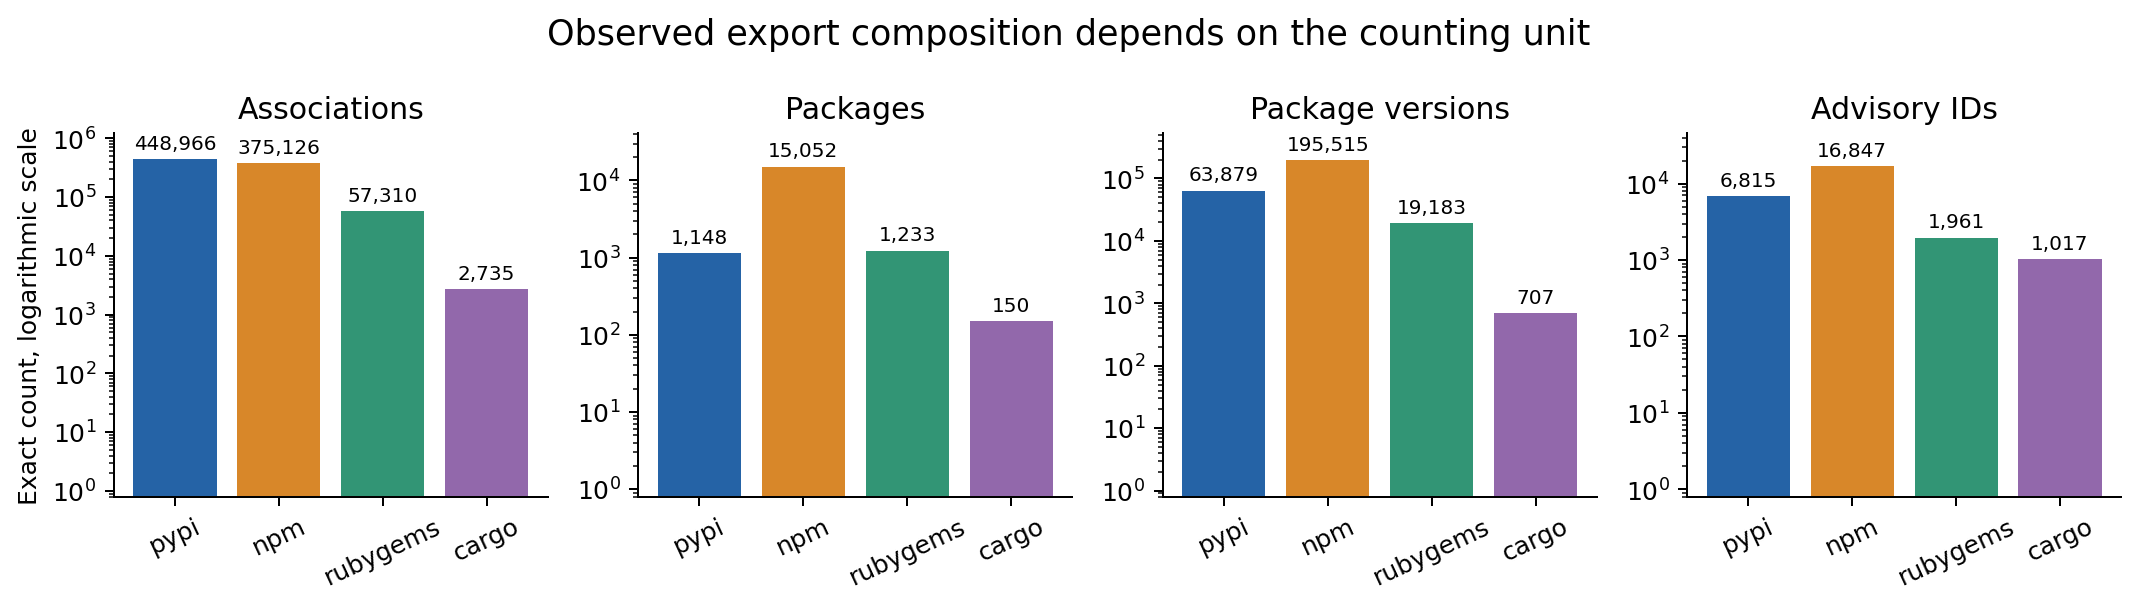

In [10]:
display(Image(filename=str(FIGURES / '01_ecosystem_composition.png')))

## 2 Quality profiles

Figure 2. Exact percentages of processed records with missing/invalid severity, a recorded zero score, or a blank description, within each ecosystem. Zero is retained separately because its source meaning is not fully documented. These percentages describe record completeness rather than missingness mechanisms.

No processed association has missing/invalid numeric severity or a blank description, but recorded-zero rates differ: RubyGems 30.84%, PyPI 30.33%, Cargo 23.62% and npm 17.15%. Thus syntactically complete fields still require semantic review before cross-ecosystem comparison. Zero is retained as a recorded value; its exporter meaning is undocumented and these observations cannot establish a random missingness mechanism or safety.

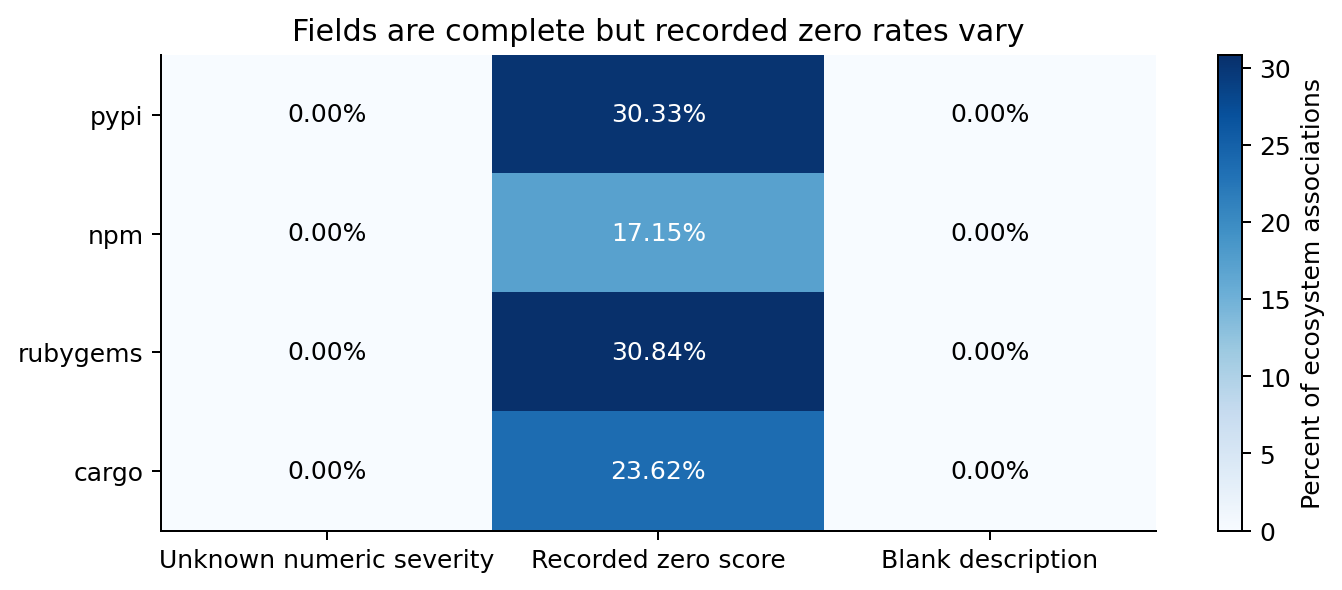

In [11]:
display(Image(filename=str(FIGURES / '02_quality_profiles.png')))

## 3 Severity bands

Figure 3. Severity-band percentages of processed associations within each ecosystem. Bands use numeric scores: zero, (0,4), [4,7), [7,9), and [9,10]. Unknown includes absent or invalid values. Scores do not establish exploitability or safety.

Scores of at least 7 account for 165,965/375,126 npm associations (44.24%) and 146,459/448,966 PyPI associations (32.62%). Because this export has no unknown numeric scores, the known-score and full-association denominators coincide in these percentages. The profiles answer the observed impact-distribution question, but repeated affected versions and source scoring conventions prevent interpreting the difference as ecosystem-wide risk.

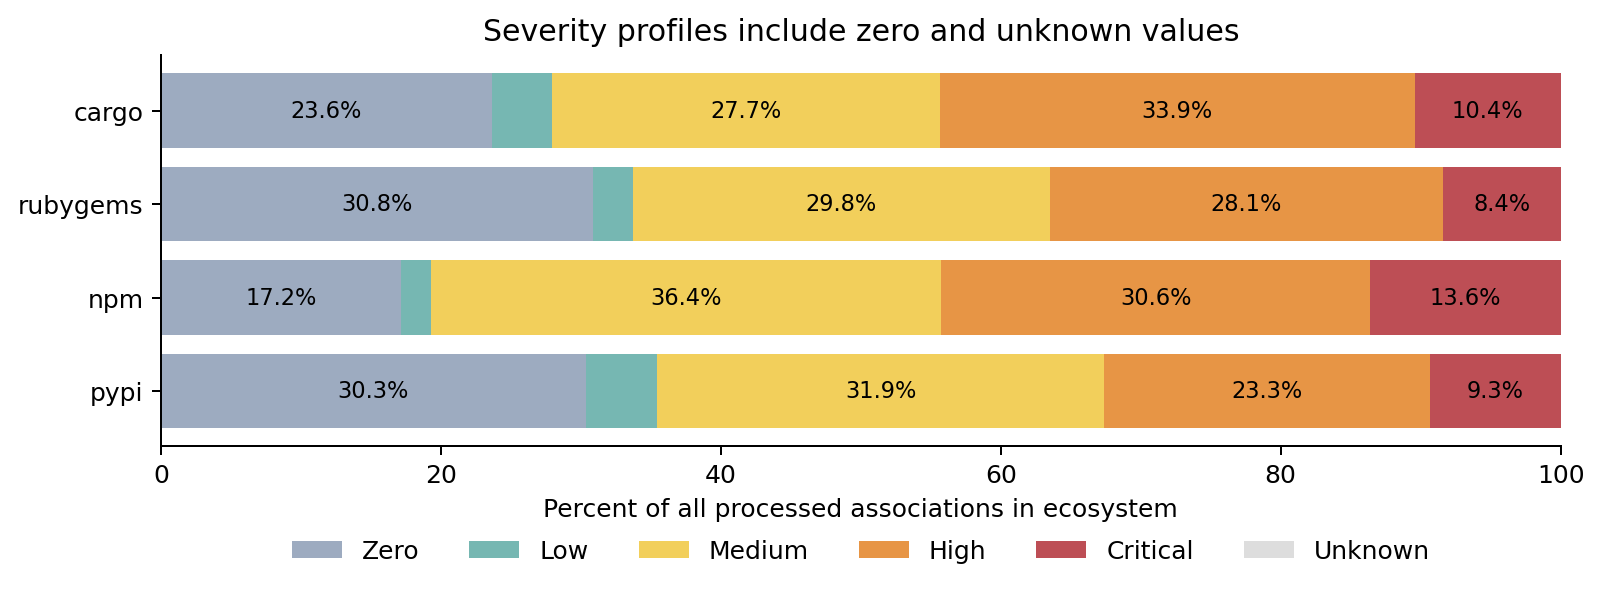

In [12]:
display(Image(filename=str(FIGURES / '03_severity_bands.png')))

## 4 Weighting ecdf

Figure 4. Empirical cumulative distributions of numeric severity for associations and for ecosystem-advisory IDs using each ID's maximum observed score. Each line excludes unknown scores and states a different estimand. Advisory aliases remain unresolved and conflicting scores can affect the maximum.

The npm high/critical share changes from 44.24% among 375,126 scored associations to 13.65% among 16,847 ecosystem-advisory maxima; PyPI changes only from 32.62% to 30.24%. Repeated links to many affected versions can substantially change an impact summary, so choosing the counting unit matters more than simply choosing a chart. Each observed ecosystem-advisory pair has one numeric score here, but unresolved aliases mean advisory IDs still cannot be assumed to represent independent vulnerabilities.

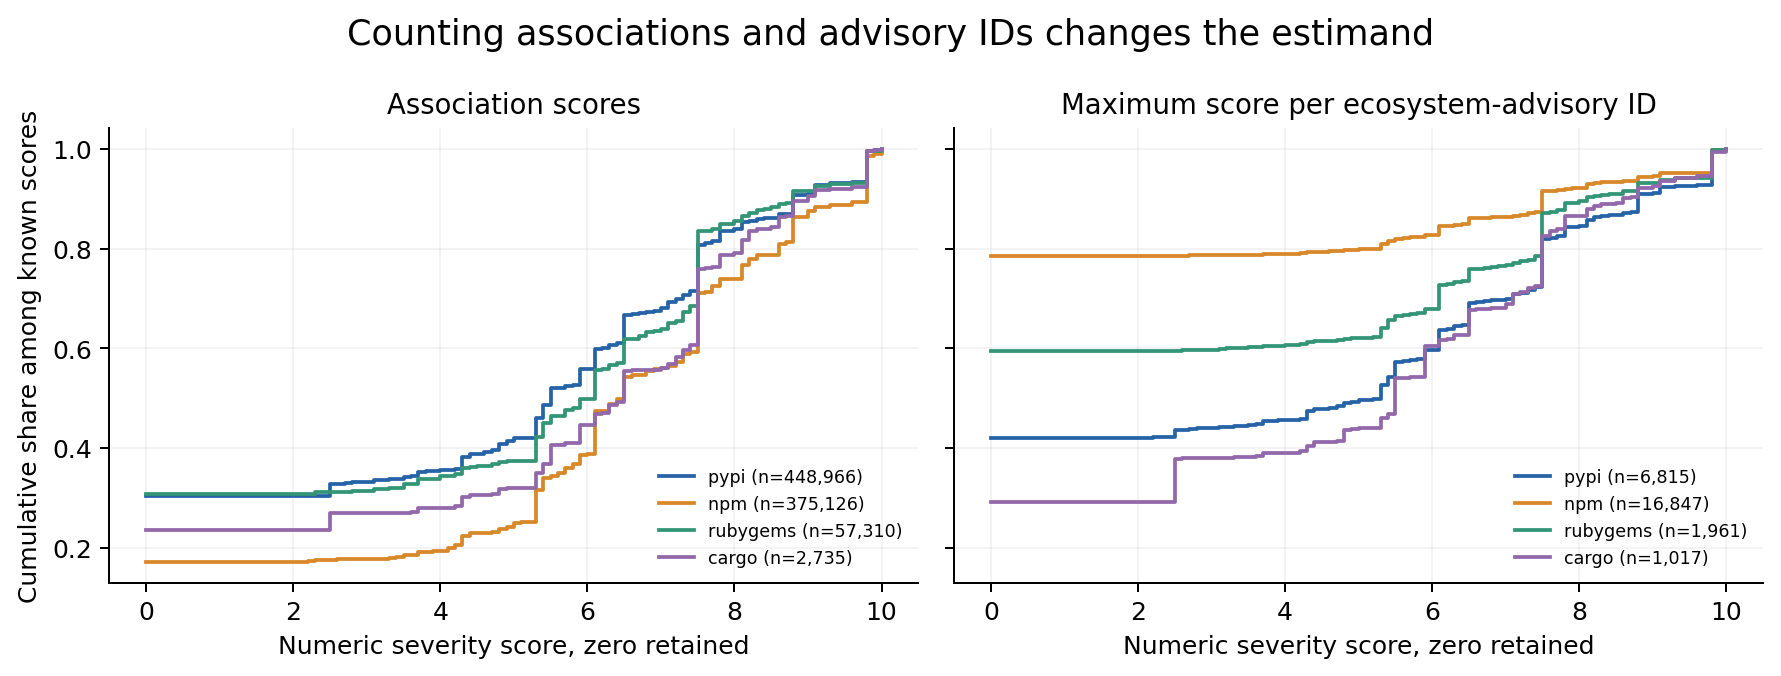

In [13]:
display(Image(filename=str(FIGURES / '04_weighting_ecdf.png')))

## 5 Package version burden

Figure 5. Distribution of distinct observed affected versions per ecosystem-qualified package. Boxes show Q1, median and Q3; whiskers use 1.5 IQR and dots show outside values. The logarithmic axis reveals skew in a vulnerable-only population without release dates.

PyPI's 1,148 observed packages have median 24 affected versions and IQR 50, compared with npm's median 1 and IQR 0 across 15,052 packages. npm nevertheless reaches 4909 versions for one package, making the long tail visible on a log axis; its zero IQR means counts above one meet the mechanical 1.5-IQR rule, not that they are invalid. Resistant summaries preserve this structure without deleting legitimate extremes, and no complete-release denominator or chronology is available.

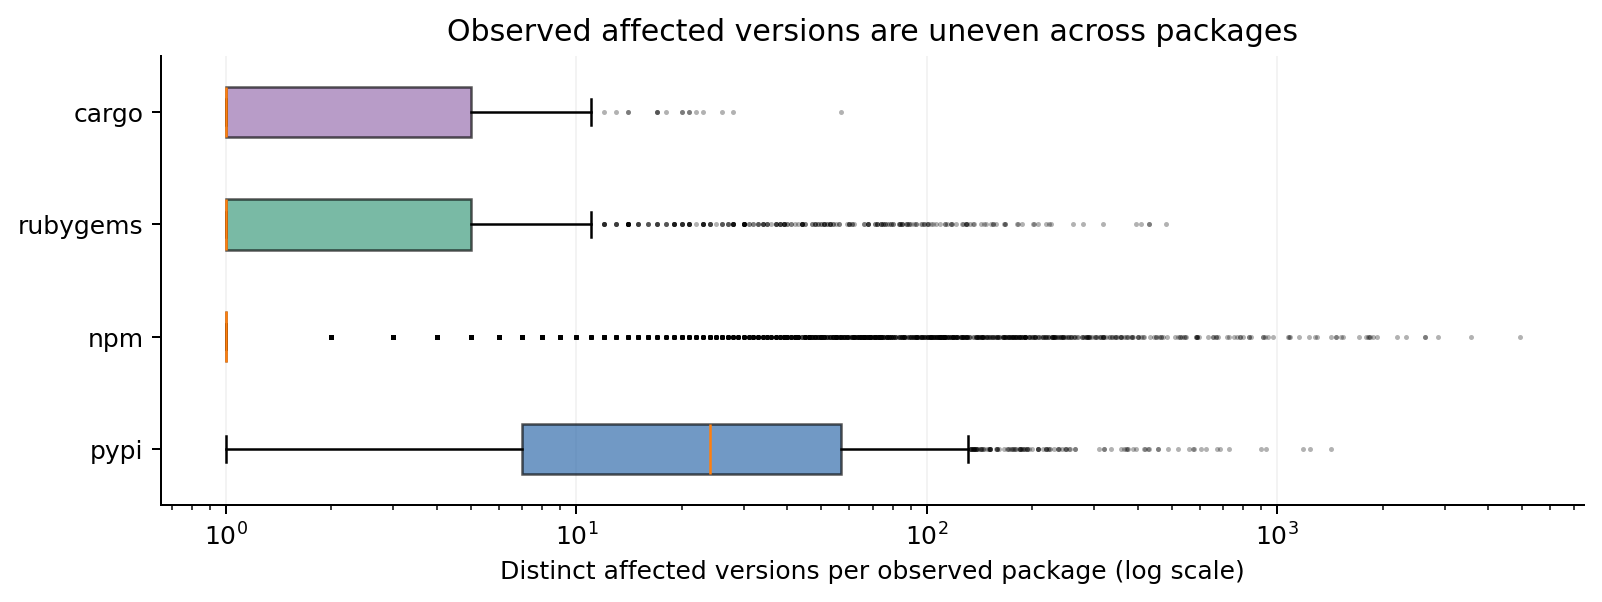

In [14]:
display(Image(filename=str(FIGURES / '05_package_version_burden.png')))

## 6 Advisory reach

Figure 6. Distinct ecosystem-qualified package versions linked to each ecosystem-advisory ID. Boxes show Q1, median and Q3; whiskers use 1.5 IQR and dots show outside values. Counts measure observed advisory reach rather than independent security events.

Median affected-package-version reach is 36 for 6,815 PyPI ecosystem-advisory IDs, 2 for RubyGems and 1 for npm and Cargo. npm's maximum of 4909 versus PyPI's 1420 shows that a small median can coexist with very broad observed advisories. This partly answers version-distribution question and supports inspection of high-burden IDs, but counts represent observed associations rather than installations, exploitation or alias-resolved security events.

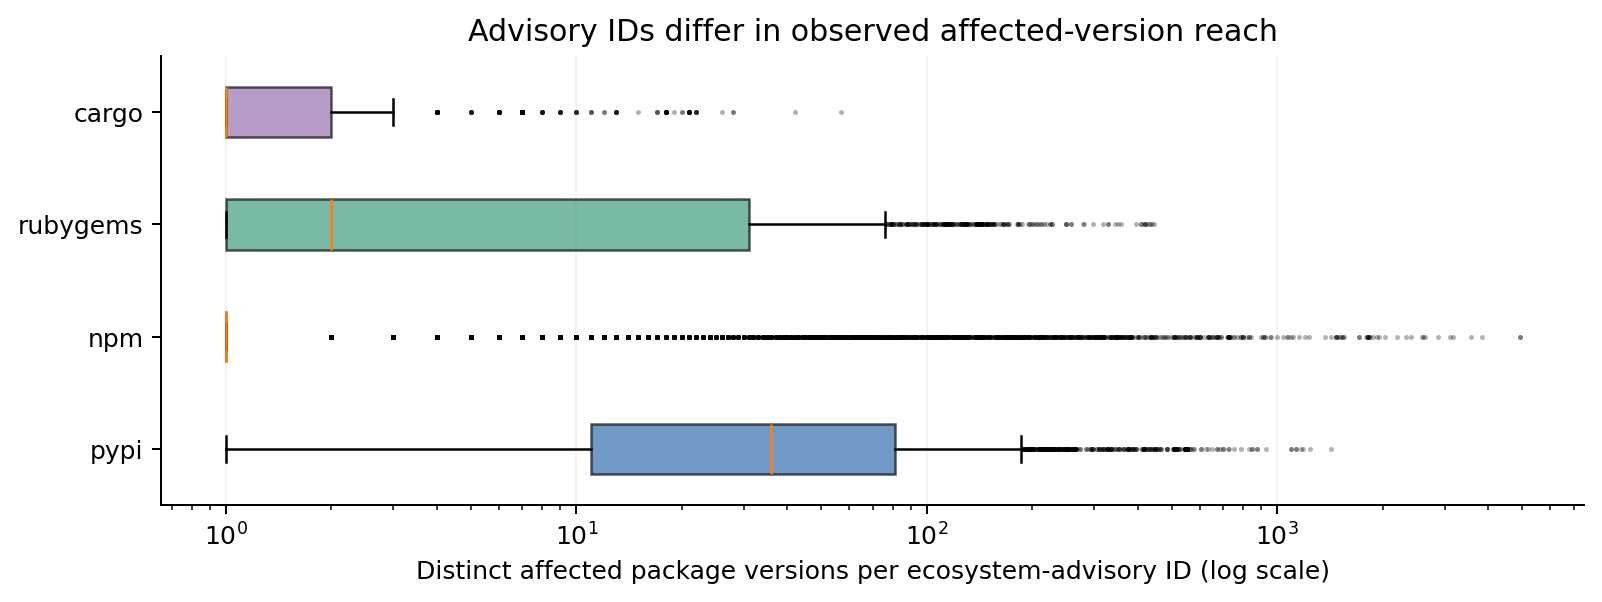

In [15]:
display(Image(filename=str(FIGURES / '06_advisory_reach.png')))

## 7 Exposure concentration

Figure 7. Lorenz curves for observed affected-version counts across ecosystem-qualified packages, sorted by burden. Axes express shares of packages and observed affected versions within each ecosystem. A package-version associated with multiple advisories contributes once to that package's burden.

The top 151 of 15,052 npm packages account for 52.41% of its 195,515 observed affected versions; the corresponding PyPI group of 12 accounts for 15.87%. This concentration suggests that a descriptive review focused on high-burden observed packages can cover many affected-version records. Each top group is ceil(1% of observed packages), and the curve measures neither installed dependency reach nor the probability a package is vulnerable.

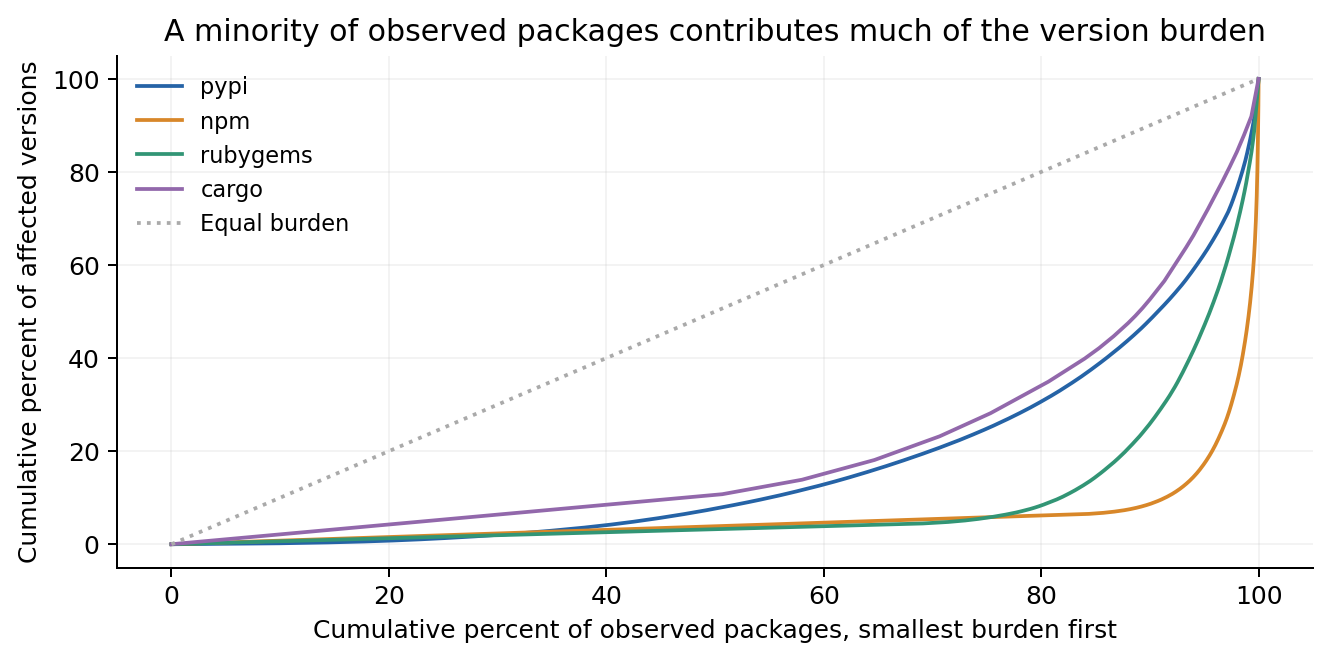

In [16]:
display(Image(filename=str(FIGURES / '07_exposure_concentration.png')))

## 8 Package count relationship

Figure 8. Logarithmic hexbin views of distinct affected-version count versus distinct advisory-ID count per package. Hexagon color shows package frequency. Spearman correlation summarizes rank association only; no regression, causal effect, or temporal trend is fitted.

Spearman correlations between distinct affected-version count and advisory-ID count are pypi 0.386 (n=1,148), npm 0.467 (n=15,052), rubygems 0.585 (n=1,233), cargo 0.241 (n=150). Positive rank associations support a relationship between the two observed burdens, while dense low-count cells, ties and sparse long tails show why one linear slope would be inadequate. Hexbin aggregation avoids overplotting; without a fitted trend there are no model residuals to diagnose, and no causal or temporal conclusion follows.

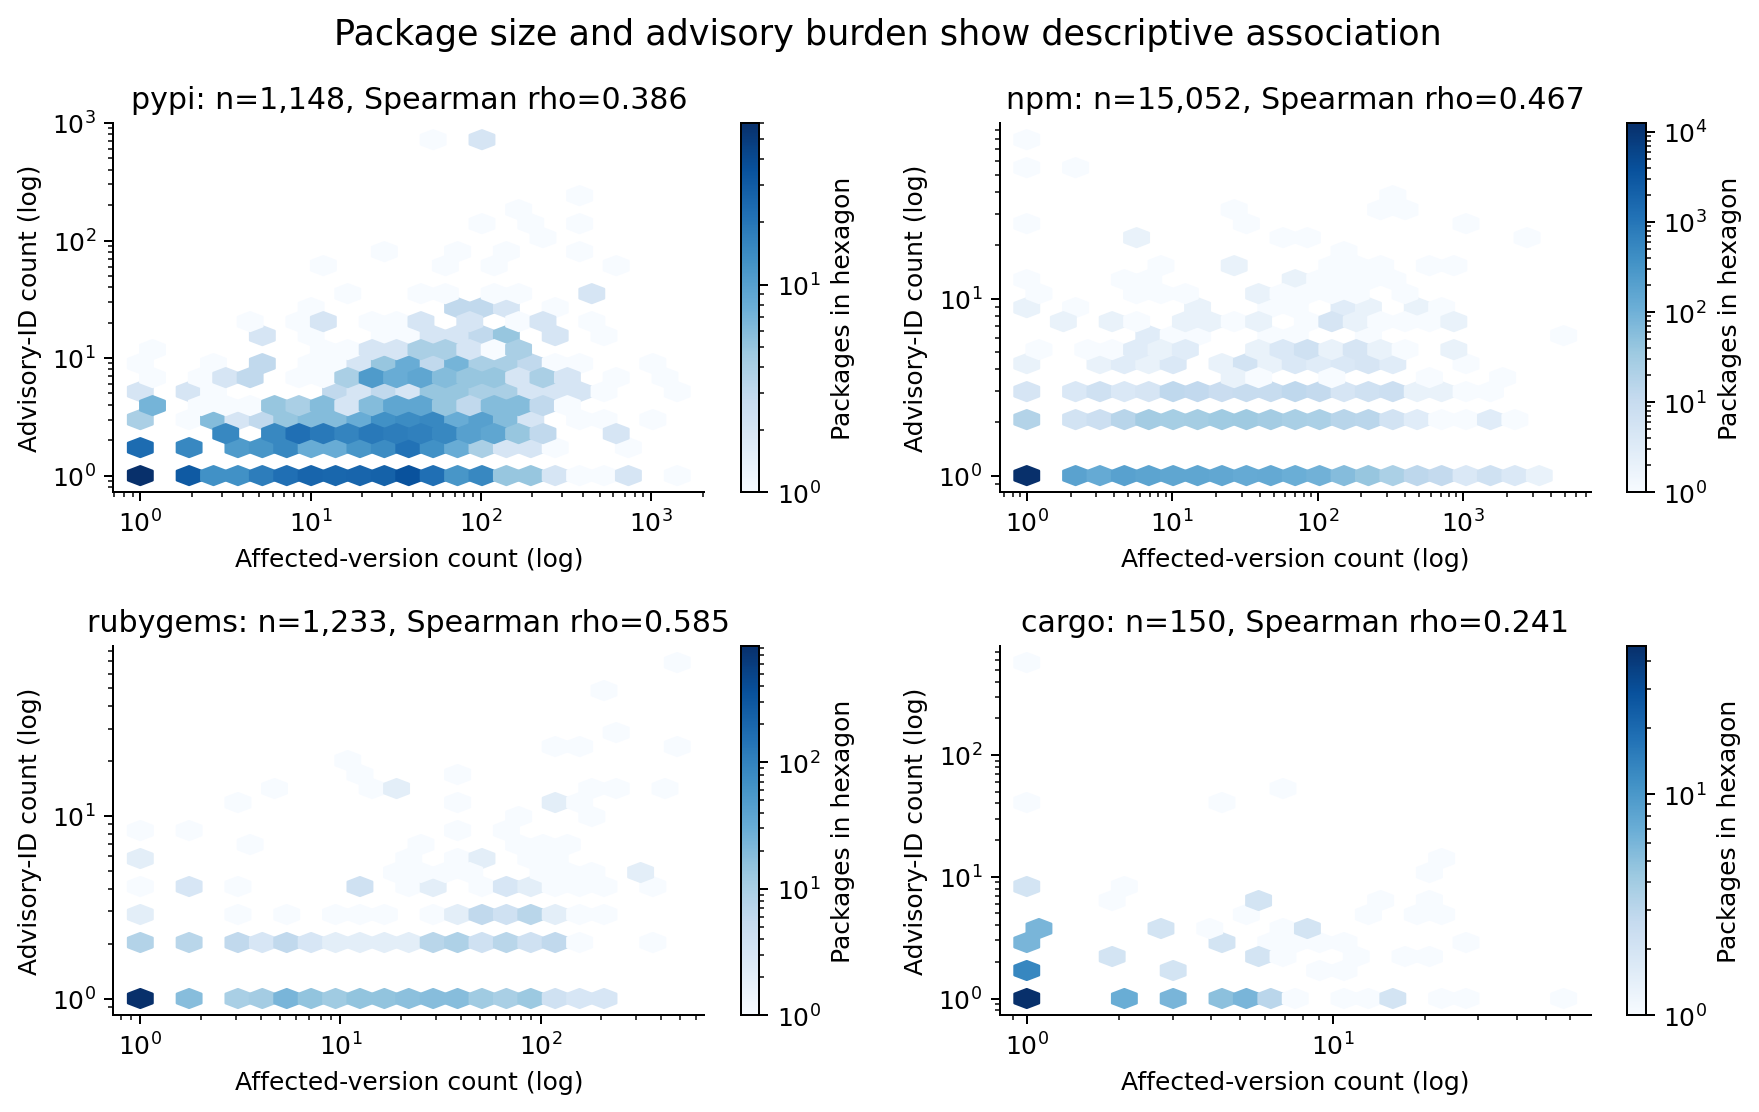

In [17]:
display(Image(filename=str(FIGURES / '08_package_count_relationship.png')))

## 9 Severity histogram

Figure 9. Exact association-weighted numeric severity distribution from processed data. Recorded zeros are counted separately from positive scores, which use 0.5-point bins on [0,10], left-closed and right-open except the final bin. Missing or invalid scores are excluded from numeric bins and reported separately; zeros do not establish safety.

Recorded zero forms a separate mass of 218,849/884,137 associations (24.75%); missing/invalid scores number 0 and never enter the numeric bins. Among positive recorded scores, exact modes include 7.5 (94,685 associations) and 9.8 (66,977), producing pronounced peaks rather than a smooth bell-shaped distribution. Half-point bins reveal broad shape while the exact frequency table preserves discrete spikes; these association-weighted peaks reflect repeated versions and score conventions, not independent vulnerability counts.

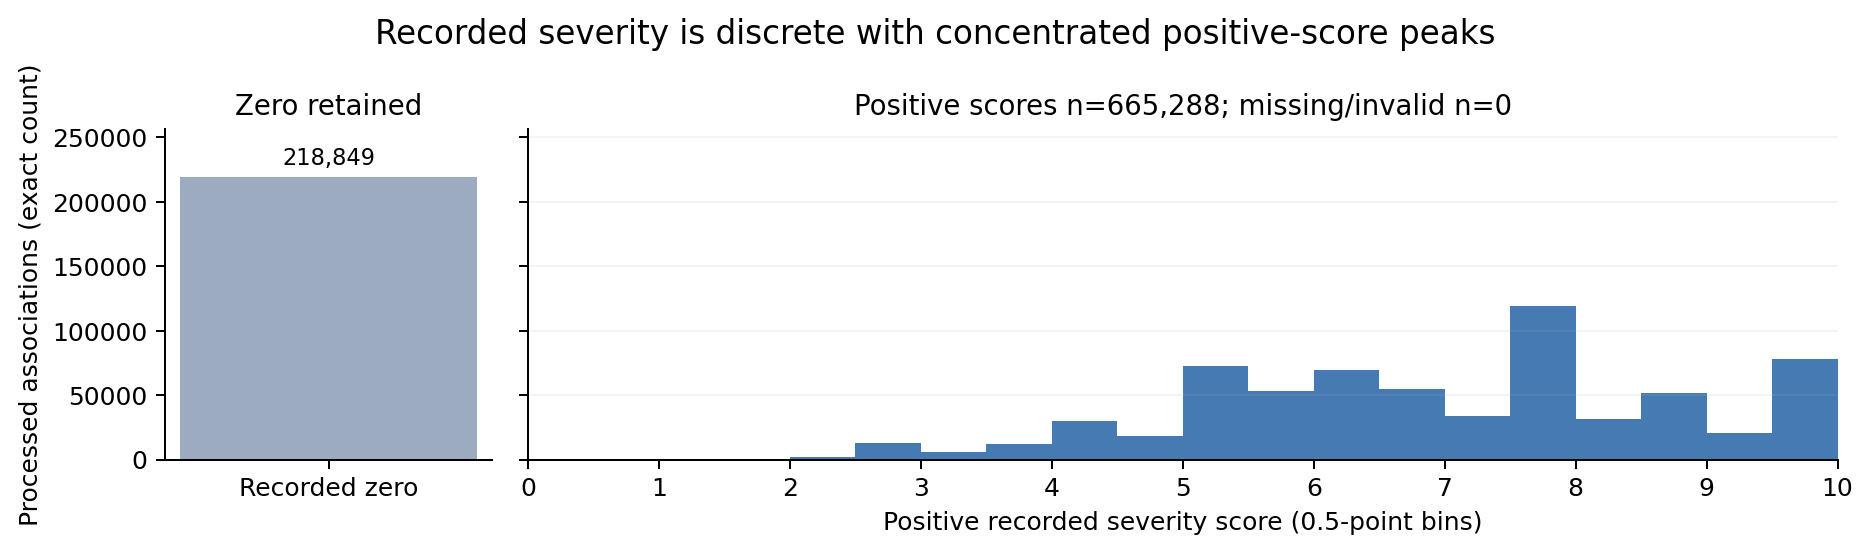

Independent zero/positive/unknown and histogram accounting passed: 218849 665288 0


In [18]:
display(Image(filename=str(FIGURES / '09_severity_histogram.png')))
# Check histogram accounting directly against the processed relation.
zero, positive, unknown = con.execute('SELECT count(*) FILTER(WHERE severity_score=0),count(*) FILTER(WHERE severity_score>0),count(*) FILTER(WHERE severity_score IS NULL) FROM a').fetchone()
H = A['severity_histogram']
assert (zero,positive,unknown) == (H['recorded_zero_associations'],H['positive_associations'],H['unknown_associations'])
assert sum(b['positive_associations'] for b in H['bins']) == positive
assert zero + positive + unknown == actual
print('Independent zero/positive/unknown and histogram accounting passed:', zero,positive,unknown)

## Quantitative answers and additional investigations

The separate result tables answer the distribution and cross-ecosystem-quality questions within the export. Full-source sampling diagnosis rejects the all-npm 250,000-row prefix; advisory-only collapse rejects deletion of legitimate version links. Correlation measures rank association across the complete observed package population, while concentration measures affected-version shares. Temporal and transitive questions remain deferred for explicitly missing metadata, and no fitted trend is used.

In [19]:
for key in ['package_burden','advisory_reach','concentration','weighting_comparison','count_relationship','advisory_conflicts','research_question_support']:
    display(Markdown('### ' + key.replace('_',' ').title()))
    print(json.dumps(A[key], indent=2))

### Package Burden

[
  {
    "package_manager": "pypi",
    "n": 1148,
    "min": 1.0,
    "q1": 7.0,
    "median": 24.0,
    "q3": 57.0,
    "max": 1420.0,
    "mean": 55.643728222996515,
    "p95": 193.0,
    "iqr": 50.0,
    "skewness": 6.110623184328455,
    "outlier_count": 114
  },
  {
    "package_manager": "npm",
    "n": 15052,
    "min": 1.0,
    "q1": 1.0,
    "median": 1.0,
    "q3": 1.0,
    "max": 4909.0,
    "mean": 12.989303747010364,
    "p95": 43.0,
    "iqr": 0.0,
    "skewness": 23.03381584223965,
    "outlier_count": 2395
  },
  {
    "package_manager": "rubygems",
    "n": 1233,
    "min": 1.0,
    "q1": 1.0,
    "median": 1.0,
    "q3": 5.0,
    "max": 482.0,
    "mean": 15.557988645579886,
    "p95": 87.39999999999986,
    "iqr": 4.0,
    "skewness": 5.508753497361188,
    "outlier_count": 253
  },
  {
    "package_manager": "cargo",
    "n": 150,
    "min": 1.0,
    "q1": 1.0,
    "median": 1.0,
    "q3": 5.0,
    "max": 57.0,
    "mean": 4.713333333333333,
    "p95": 20.0,
    "

### Advisory Reach

[
  {
    "package_manager": "pypi",
    "n": 6815,
    "min": 1.0,
    "q1": 11.0,
    "median": 36.0,
    "q3": 81.0,
    "max": 1420.0,
    "mean": 65.87909024211298,
    "p95": 213.0,
    "iqr": 70.0,
    "skewness": 4.5035455950408565,
    "outlier_count": 450
  },
  {
    "package_manager": "npm",
    "n": 16847,
    "min": 1.0,
    "q1": 1.0,
    "median": 1.0,
    "q3": 1.0,
    "max": 4909.0,
    "mean": 22.266635009200453,
    "p95": 95.69999999999891,
    "iqr": 0.0,
    "skewness": 17.41802372830819,
    "outlier_count": 3938
  },
  {
    "package_manager": "rubygems",
    "n": 1961,
    "min": 1.0,
    "q1": 1.0,
    "median": 2.0,
    "q3": 31.0,
    "max": 444.0,
    "mean": 29.22488526262111,
    "p95": 139.0,
    "iqr": 30.0,
    "skewness": 3.4668107284084186,
    "outlier_count": 256
  },
  {
    "package_manager": "cargo",
    "n": 1017,
    "min": 1.0,
    "q1": 1.0,
    "median": 1.0,
    "q3": 2.0,
    "max": 57.0,
    "mean": 2.689282202556539,
    "p95": 10.0,


### Concentration

...

[
  {
    "package_manager": "pypi",
    "n_packages": 1148,
    "spearman_rho": 0.3862031903751967,
    "method": "Exact rank correlation on all processed ecosystem-qualified packages; no fitted trend"
  },
  {
    "package_manager": "npm",
    "n_packages": 15052,
    "spearman_rho": 0.4673264984964335,
    "method": "Exact rank correlation on all processed ecosystem-qualified packages; no fitted trend"
  },
  {
    "package_manager": "rubygems",
    "n_packages": 1233,
    "spearman_rho": 0.5851009730587957,
    "method": "Exact rank correlation on all processed ecosystem-qualified packages; no fitted trend"
  },
  {
    "package_manager": "cargo",
    "n_packages": 150,
    "spearman_rho": 0.24089883180030489,
    "method": "Exact rank correlation on all processed ecosystem-qualified packages; no fitted trend"
  }
]


### Advisory Conflicts

[
  {
    "package_manager": "npm",
    "advisory_ids": 16847,
    "multi_score_ids": 0,
    "maximum_scores_per_id": 1
  },
  {
    "package_manager": "pypi",
    "advisory_ids": 6815,
    "multi_score_ids": 0,
    "maximum_scores_per_id": 1
  },
  {
    "package_manager": "rubygems",
    "advisory_ids": 1961,
    "multi_score_ids": 0,
    "maximum_scores_per_id": 1
  },
  {
    "package_manager": "cargo",
    "advisory_ids": 1017,
    "multi_score_ids": 0,
    "maximum_scores_per_id": 1
  }
]


### Research Question Support

[
  {
    "question": "Distribution across ecosystems, versions and impact",
    "status": "Partially answered",
    "reason": "Exact distributions within observed association export; all-version prevalence and alias-resolved advisory counts require enrichment"
  },
  {
    "question": "Recent versus older vulnerable versions",
    "status": "Deferred",
    "reason": "CSV has no release timestamps or reliable ecosystem-specific latest-release ordering"
  },
  {
    "question": "Cross-ecosystem quality and structure",
    "status": "Answered for CSV",
    "reason": "Exact field, key, severity and subgroup profiles; database validation remains separate"
  },
  {
    "question": "Direct versus transitive exposure",
    "status": "Deferred",
    "reason": "CSV has no dependency edges, constraints or resolved dependency versions"
  }
]


## Reproducibility and scope of verification

Configuration determines processed, results and figure paths, rather than historical paths saved in an older receipt. `PHASE2_CONFIG` optionally selects another configuration file. A checksum binds the reloaded Parquet to its analytical results; the final cell independently recomputes exact entity counts. Clean-kernel execution demonstrates computational consistency but cannot establish student authorship, personal participation or a new dependency environment; those require separate evidence.

In [20]:
# Recompute distinct entities without trusting the JSON summary.
assert con.execute('SELECT count(DISTINCT (package_manager,package_name)) FROM a').fetchone()[0] == A['totals']['packages']
assert con.execute('SELECT count(DISTINCT (package_manager,package_name,version_name)) FROM a').fetchone()[0] == A['totals']['versions']
assert con.execute('SELECT count(DISTINCT vuln_id) FROM a').fetchone()[0] == A['totals']['advisory_ids']
assert con.execute('SELECT count(DISTINCT (package_manager,vuln_id)) FROM a').fetchone()[0] == A['totals']['ecosystem_advisory_ids']
for stem in A['figure_captions']:
    assert (FIGURES / (stem + '.png')).is_file()
con.close()
print('Processed reload, exact entity counts and all nine figure links verified.')

Processed reload, exact entity counts and all nine figure links verified.
